(3498, 12)
             timestamp    workload  inlet_temp  outlet_temp  ambient_temp  \
0  2025-01-01 00:00:00  100.000000   24.726323    28.469324     21.424454   
1  2025-01-01 01:00:00   87.358993   23.085262    29.854364     26.420271   
2  2025-01-01 02:00:00   19.313800   16.288791    23.381846     21.452172   
3  2025-01-01 03:00:00   41.406680   19.217280    24.323699     19.200412   
4  2025-01-01 04:00:00   49.514889   19.991740    23.205543     26.768503   

   cooling_power    chiller        ahu  energy_cost  temp_dev    strategy  \
0           0.98  94.205859  45.462911         0.09      2.58  Reduce AHU   
1           0.95  85.776996  53.185858         0.10      2.42    Eco Mode   
2           0.43  28.148672  40.833469         0.06      2.55    Eco Mode   
3           0.61  49.300227  42.490922         0.08      4.80   Boost All   
4           0.69  49.656127  58.100890         0.10      2.77    Eco Mode   

   output  
0       1  
1       4  
2       4  
3       3  
4  

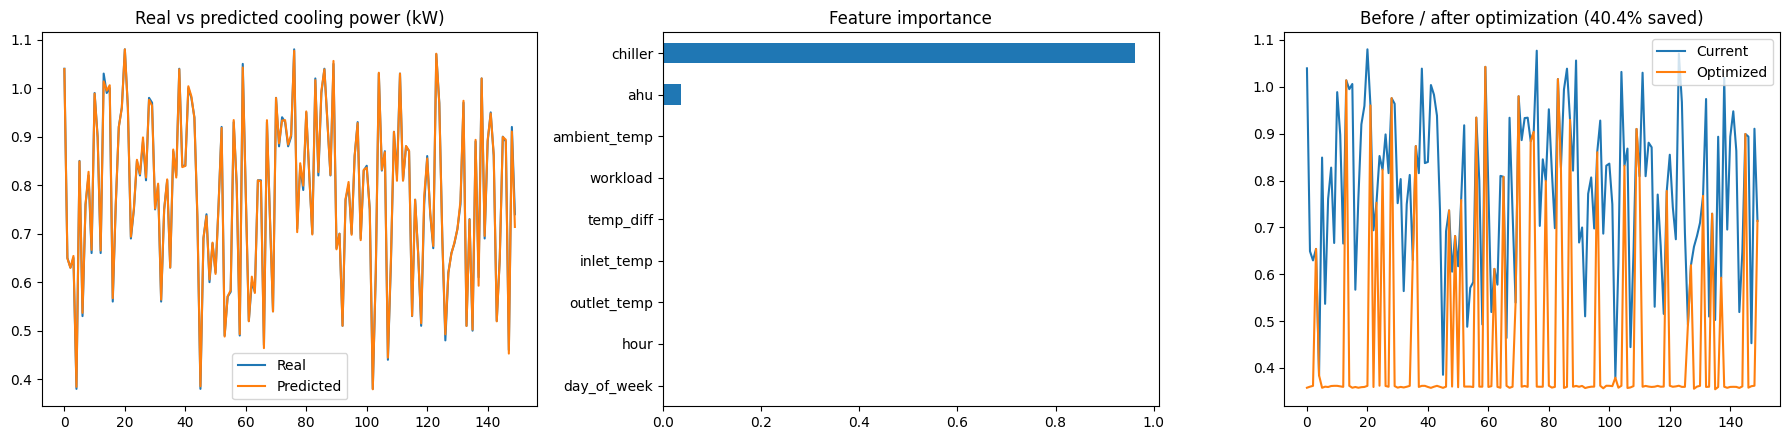

In [1]:
# Project 19 - Person 3: Random Forest - HVAC Optimization
# Dataset: green cold_source_control_dataset (3498 rows, 12 columns)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# -----------------------------------------------------------------
# 1. Load data
# -----------------------------------------------------------------
import glob
path = glob.glob('/kaggle/input/**/cold_source*.csv', recursive=True)[0]

df = pd.read_csv(path)
# Rename columns by position (easy names, no strange spaces)
df.columns = ['timestamp', 'workload', 'inlet_temp', 'outlet_temp',
              'ambient_temp', 'cooling_power', 'chiller', 'ahu',
              'energy_cost', 'temp_dev', 'strategy', 'output']
print(df.shape)
print(df.head())
print(df['strategy'].value_counts().head())
print(df['output'].value_counts().head())
# -----------------------------------------------------------------
# 2. Preprocessing
# -----------------------------------------------------------------
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').drop_duplicates('timestamp')
num_cols = ['workload', 'inlet_temp', 'outlet_temp', 'ambient_temp',
            'cooling_power', 'chiller', 'ahu', 'energy_cost', 'temp_dev']
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek
df['temp_diff'] = df['outlet_temp'] - df['inlet_temp']
# -----------------------------------------------------------------
# 3. Feature selection
# -----------------------------------------------------------------
TARGET = 'cooling_power'
# We do NOT use energy_cost (it is made from power = leakage)
# We do NOT use temp_dev as input (it is a result, we use it as a safety check)
features = ['workload', 'inlet_temp', 'outlet_temp', 'ambient_temp',
            'chiller', 'ahu', 'hour', 'day_of_week', 'temp_diff']
corr = df[features + [TARGET]].corr()[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print('\nCorrelation with target:\n', corr)
X = df[features]
y = df[TARGET]
y_dev = df['temp_dev']
X_train, X_test, y_train, y_test, d_train, d_test = train_test_split(
    X, y, y_dev, test_size=0.2, shuffle=False)
# -----------------------------------------------------------------
# 4. Random Forest model (energy / cooling power)
# -----------------------------------------------------------------
rf = RandomForestRegressor(n_estimators=200, max_depth=12,
                           min_samples_leaf=3, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
# Second model: temperature deviation (safety check)
rf_dev = RandomForestRegressor(n_estimators=200, max_depth=12,
                               min_samples_leaf=3, random_state=42, n_jobs=-1)
rf_dev.fit(X_train, d_train)
# -----------------------------------------------------------------
# 5. Energy consumption prediction
# -----------------------------------------------------------------
pred = rf.predict(X_test)
print('\nMAE  =', round(mean_absolute_error(y_test, pred), 4))
print('RMSE =', round(np.sqrt(mean_squared_error(y_test, pred)), 4))
print('R2   =', round(r2_score(y_test, pred), 4))
# -----------------------------------------------------------------
# 6. HVAC optimization
# -----------------------------------------------------------------
# For each hour, try different chiller and AHU levels.
# Keep only the settings where predicted temperature deviation is safe.
# Choose the setting with the lowest predicted cooling power.
DEV_LIMIT = df['temp_dev'].quantile(0.75)   # safe limit (you can change)
chiller_vals = np.linspace(df['chiller'].min(), df['chiller'].max(), 10)
ahu_vals = np.linspace(df['ahu'].min(), df['ahu'].max(), 10)
best_power = pred.copy()          # start with current prediction
best_chiller = X_test['chiller'].values.copy()
best_ahu = X_test['ahu'].values.copy()
for ch in chiller_vals:
    for ah in ahu_vals:
        tmp = X_test.copy()
        tmp['chiller'] = ch
        tmp['ahu'] = ah
        p = rf.predict(tmp)
        dev = rf_dev.predict(tmp)
        better = (p < best_power) & (dev <= DEV_LIMIT)
        best_power[better] = p[better]
        best_chiller[better] = ch
        best_ahu[better] = ah
saving_pct = 100 * (pred.sum() - best_power.sum()) / pred.sum()
print(f'\nEstimated cooling power saving: {saving_pct:.2f} %')
print('NOTE: this is a model estimate, not a real measurement.')
# -----------------------------------------------------------------
# Plots
# -----------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(y_test.values[:150], label='Real')
ax[0].plot(pred[:150], label='Predicted')
ax[0].set_title('Real vs predicted cooling power (kW)')
ax[0].legend()
pd.Series(rf.feature_importances_, 
index=features).sort_values().plot(kind='barh', ax=ax[1])
ax[1].set_title('Feature importance')
ax[2].plot(pred[:150], label='Current')
ax[2].plot(best_power[:150], label='Optimized')
ax[2].set_title(f'Before / after optimization ({saving_pct:.1f}% saved)')
ax[2].legend()
plt.tight_layout()
plt.savefig('person3_results.png', dpi=150)
plt.show()